# ApexPlanet Internship – Task 1
## Foundational Setup & Exploratory Data Analysis (EDA)

**Dataset:** Sample Superstore (retail orders)  
**Goal:** Inspect, clean, and explore sales data; save a clean dataset and visual evidence.

> Run all cells from top to bottom. The first cell downloads the public CSV dataset into `data/raw/`.

### 1. Import libraries and setup

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROJECT_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
CLEAN_DIR = os.path.join(PROJECT_ROOT, "data", "cleaned")
REPORT_DIR = os.path.join(PROJECT_ROOT, "reports")
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(CLEAN_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

### 2. Download and load the dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/leonism/sample-superstore/master/data/superstore.csv"
raw_file = os.path.join(RAW_DIR, "sample_superstore.csv")

if not os.path.exists(raw_file):
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, raw_file)

df_raw = pd.read_csv(raw_file, dtype={"Postal Code": "string"})
df = df_raw.copy()

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   string 
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

None

### 3. Initial data inspection

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Rows and columns: (10800, 21)
\nColumn names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
\nMissing values per column:


,missing_count
Postal Code,817
Ship Mode,806
Ship Date,806
Customer ID,806
Order Date,806
Product ID,806
Category,806
Segment,806
Customer Name,806
Country,806


\nDuplicate rows: 504


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10800,10001,Yes,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,10800,5015,CA-2018-100111,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1236,9/5/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Data cleaning

In [4]:
# Standardize column labels by trimming accidental whitespace.
df.columns = df.columns.str.strip()

# Remove exact duplicate rows.
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Convert date columns to datetime.
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns safely.
numeric_cols = ["Sales", "Quantity", "Discount", "Profit", "Postal Code", "Row ID"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill numeric missing values with median; categorical missing values with mode.
for col in df.select_dtypes(include=["number"]).columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "string"]).columns:
    if df[col].isna().any():
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# Keep postal codes as strings for display and preserve leading zeros.
if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].round().astype("Int64").astype("string")

# Feature engineering for analysis.
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"], np.nan)

print("Exact duplicate rows removed:", duplicates_removed)
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Cleaned shape:", df.shape)
display(df.head())

Exact duplicate rows removed: 504
Remaining missing values: 1208
Cleaned shape: (10296, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Shipping Days,Profit Margin
0,1.00,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91,"2,017.00",2017-11,3.00,0.16
1,2.00,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58,"2,017.00",2017-11,3.00,0.30
2,3.00,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87,"2,017.00",2017-06,4.00,0.47
3,4.00,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03,"2,016.00",2016-10,7.00,-0.40
4,5.00,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52,"2,016.00",2016-10,7.00,0.11


### 5. Outlier detection using the IQR method

In [5]:
# Detect outliers in numeric business measures. We flag them rather than
# automatically deleting them because unusually large orders can be genuine.
outlier_summary = []
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_summary.append({
        "Column": col, "Q1": q1, "Q3": q3,
        "Lower_Bound": lower, "Upper_Bound": upper,
        "Outlier_Count": count
    })
outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)

,Column,Q1,Q3,Lower_Bound,Upper_Bound,Outlier_Count
0,Sales,17.90,201.00,-256.74,475.64,1250
1,Quantity,2.00,5.00,-2.50,9.50,170
2,Discount,0.00,0.20,-0.30,0.50,856
3,Profit,1.90,28.17,-37.50,67.58,1966


### 6. Save cleaned dataset and quality report

In [6]:
clean_file = os.path.join(CLEAN_DIR, "superstore_cleaned.csv")
df.to_csv(clean_file, index=False)

quality_report = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(x) for x in df.dtypes],
    "missing_values": [int(x) for x in df.isna().sum()],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns]
})
quality_file = os.path.join(REPORT_DIR, "data_quality_report.csv")
quality_report.to_csv(quality_file, index=False)

print("Saved:", clean_file)
print("Saved:", quality_file)

Saved: /content/data/cleaned/superstore_cleaned.csv
Saved: /content/reports/data_quality_report.csv


### 7. Statistical summary and key performance indicators

In [7]:
display(df[["Sales", "Profit", "Quantity", "Discount", "Shipping Days", "Profit Margin"]].describe().T)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique() if "Order ID" in df.columns else len(df)
total_customers = df["Customer ID"].nunique() if "Customer ID" in df.columns else np.nan

print(f"Total sales: ${total_sales:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Unique orders: {total_orders:,}")
print(f"Unique customers: {total_customers:,}")
print(f"Overall profit margin: {total_profit / total_sales:.2%}")

,count,mean,std,min,25%,50%,75%,max
Sales,"10,296.00",224.71,614.75,0.44,17.90,54.49,201.00,"22,638.48"
Profit,"10,296.00",28.07,230.82,"-6,599.98",1.90,8.67,28.17,"8,399.98"
Quantity,"10,296.00",3.77,2.20,1.00,2.00,3.00,5.00,14.00
Discount,"10,296.00",0.16,0.20,0.00,0.00,0.20,0.20,0.80
Shipping Days,"9,994.00",3.96,1.75,0.00,3.00,4.00,5.00,7.00
Profit Margin,"10,296.00",0.12,0.46,-2.75,0.07,0.26,0.36,0.50


Total sales: $2,313,656.84
Total profit: $289,014.30
Unique orders: 5,015
Unique customers: 793
Overall profit margin: 12.49%


### 8. Visualizations

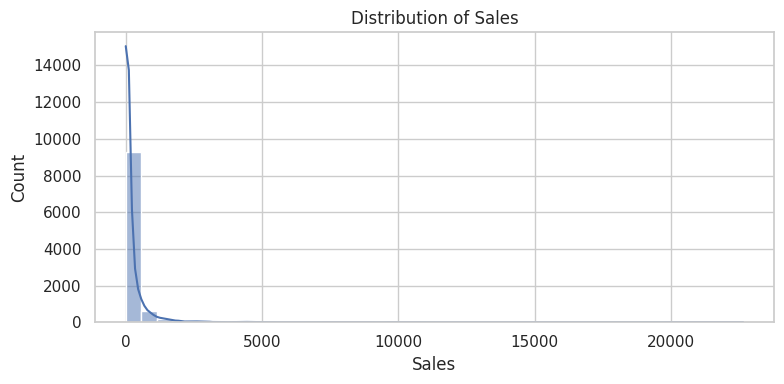

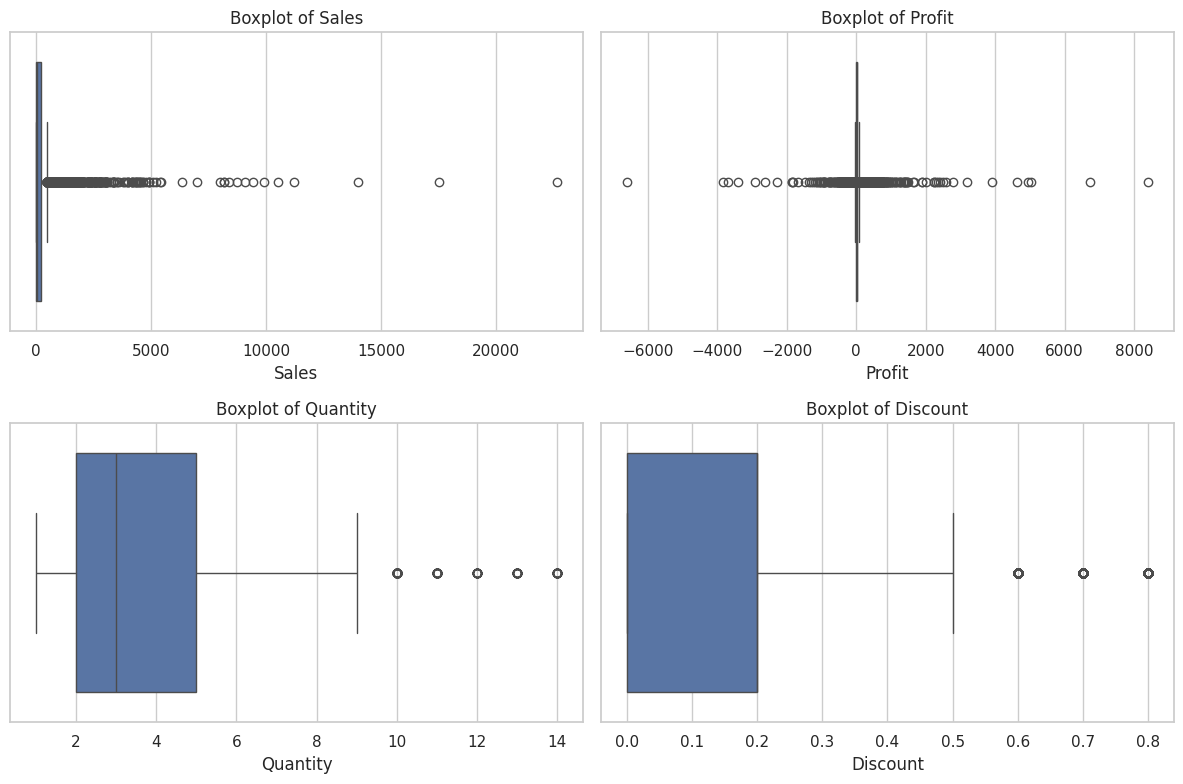

,Category,Sales,Profit
0,Furniture,"741,999.80","18,451.27"
1,Office Supplies,"735,503.01","125,108.08"
2,Technology,"836,154.03","145,454.95"


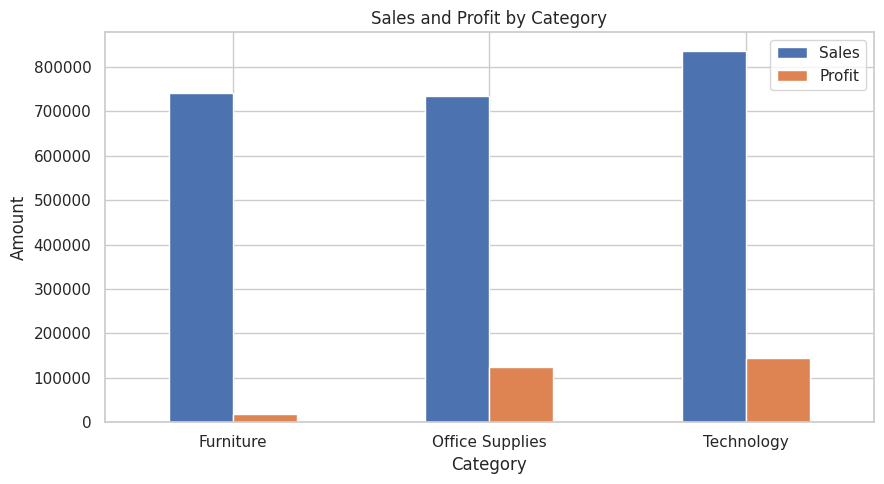

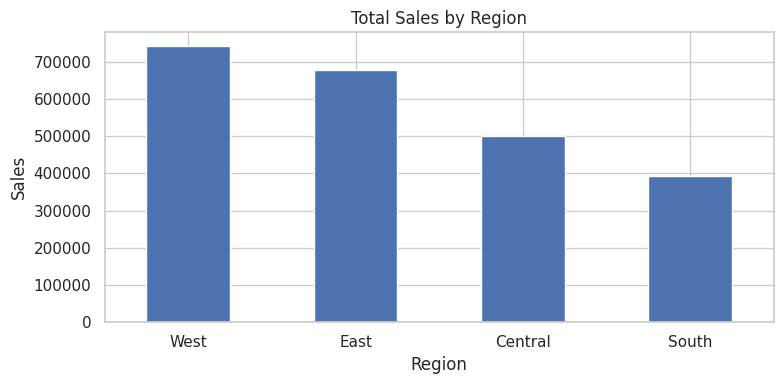

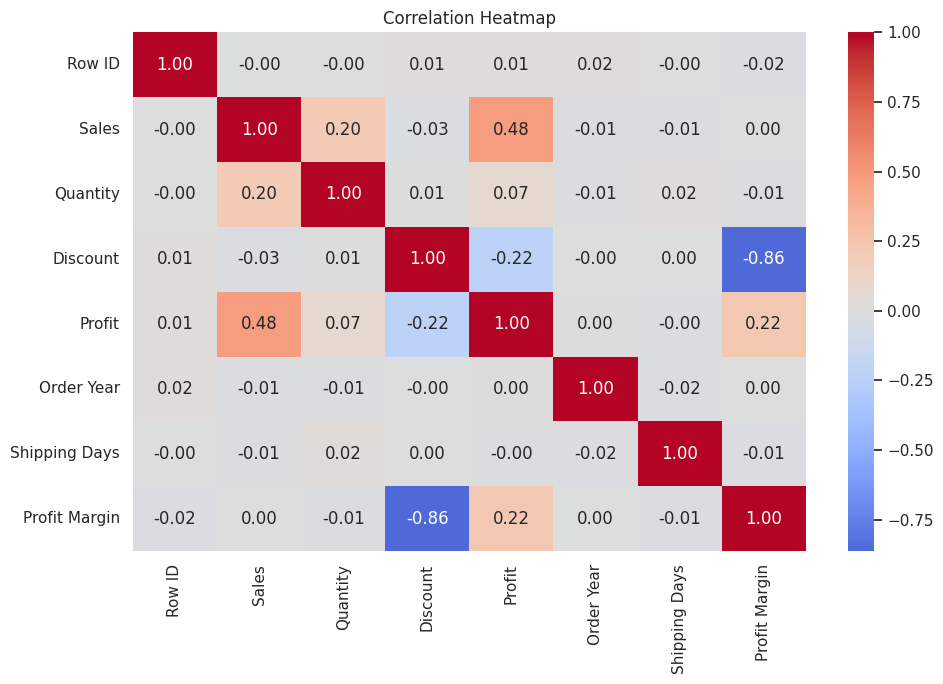

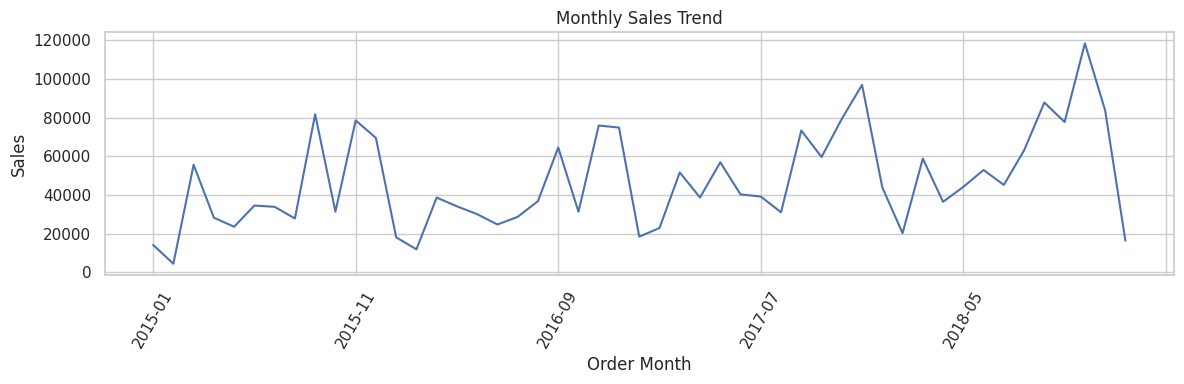

In [8]:
# Histogram: sales distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["Sales"], bins=40, kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "01_sales_histogram.png"), dpi=150)
plt.show()

# Boxplots: numeric variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ["Sales", "Profit", "Quantity", "Discount"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "02_numeric_boxplots.png"), dpi=150)
plt.show()

# Bar chart: sales and profit by category
category_summary = df.groupby("Category", as_index=False)[["Sales", "Profit"]].sum()
display(category_summary)
category_summary.set_index("Category")[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 5))
plt.title("Sales and Profit by Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "03_category_sales_profit.png"), dpi=150)
plt.show()

# Bar chart: sales by region
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_sales.plot(kind="bar", figsize=(8, 4))
plt.title("Total Sales by Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "04_region_sales.png"), dpi=150)
plt.show()

# Correlation heatmap
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "05_correlation_heatmap.png"), dpi=150)
plt.show()

# Monthly sales trend (dataset includes order dates)
monthly_sales = df.groupby("Order Month")["Sales"].sum().sort_index()
plt.figure(figsize=(12, 4))
monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(os.path.join(REPORT_DIR, "06_monthly_sales_trend.png"), dpi=150)
plt.show()

### 9. Five data-driven insights

In [9]:
# Calculate findings directly from the cleaned dataset.
top_category = df.groupby("Category")["Sales"].sum().idxmax()
top_category_sales = df.groupby("Category")["Sales"].sum().max()

top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_region_sales = df.groupby("Region")["Sales"].sum().max()

least_profitable_subcategory = df.groupby("Sub-Category")["Profit"].sum().idxmin()
least_subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().min()

loss_rows = int((df["Profit"] < 0).sum())
loss_pct = loss_rows / len(df) * 100

discount_groups = df.assign(
    Discount_Band=pd.cut(df["Discount"], bins=[-0.001, 0, 0.2, 0.5, 1.0],
                         labels=["No discount", "Up to 20%", "20%-50%", "Above 50%"])
).groupby("Discount_Band", observed=False)["Profit"].mean()

insights = [
    f"{top_category} is the top sales category with total sales of ${top_category_sales:,.2f}.",
    f"{top_region} is the highest-sales region with total sales of ${top_region_sales:,.2f}.",
    f"{least_profitable_subcategory} has the lowest total profit (${least_subcategory_profit:,.2f}) among sub-categories.",
    f"{loss_rows:,} order lines ({loss_pct:.1f}%) have negative profit.",
    "Average profit by discount band: " + "; ".join(
        [f"{str(idx)} = ${val:,.2f}" for idx, val in discount_groups.items() if pd.notna(val)]
    )
]

for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

with open(os.path.join(REPORT_DIR, "key_insights.txt"), "w", encoding="utf-8") as f:
    f.write("\\n".join(f"{i}. {x}" for i, x in enumerate(insights, 1)))

1. Technology is the top sales category with total sales of $836,154.03.
2. West is the highest-sales region with total sales of $741,913.80.
3. Tables has the lowest total profit ($-17,725.48) among sub-categories.
4. 1,871 order lines (18.2%) have negative profit.
5. Average profit by discount band: No discount = $66.90; Up to 20% = $25.19; 20%-50% = $-109.53; Above 50% = $-89.44
